# FOM / mu Formula Validation (Analytic Gaussian, No DHT)

Sanity-checks the figure-of-merit (`FOM`) and shape-correlation (`mu`) formulas — the same ones used throughout the optimizers in `common/adjoint_*_zernike.py` — against a closed-form paraxial Gaussian-through-lens field (`amp()`), not a DHT-propagated field. Scans a comparison mirror's focal length `z` across the true target focus `z=f` and confirms `FOM` and `mu` are well-behaved and correctly peak/converge to the expected values at the true match — i.e. that these objective-function formulas are mathematically sound independent of any numerical propagation error.

Note: the cell defining `S()` calls an undefined `w()` and uses `mu` as a bare function reference instead of `mu(...)` — dead/broken code left over from an earlier draft, unused by the rest of the notebook.


In [2]:
import numpy as np
from scipy.integrate import trapezoid,simpson,romb
from scipy.special import jv,jn_zeros
import matplotlib.pyplot as plt
font = {'size'   : 28}

plt.rc('font', **font)
plt.rcParams['figure.figsize'] = (16,9)

In [2]:
def DHTarrays(N,R,ell):
    Zeroes=jn_zeros(ell,N)
    r=R*Zeroes[:N]/Zeroes[N-1]
    k=Zeroes[:N]/R
    return np.array([r,k])

In [3]:
def percent_error(obs,exp):
    return(np.abs(obs-exp)/exp*100)

In [4]:
def retrieve_bounds(z,zi,zf):
    i=len(z[z-zi<0])
    f=len(z[z-zf<=0])
    return i,f

In [4]:
def w_xp(r,fn,wl):
    R=2/np.pi*fn*wl
    return np.exp(-r**2/R**2)

In [5]:
def w_z(z,zi,zf):
    i,f=retrieve_bounds(z,zi,zf)
    w=np.zeros(len(z))
    w[i:f]=1
    return w

In [6]:
def integrate(z,phi1,phi2,method=simpson):
    return method(phi1*phi2,z)    
    #return method(np.abs(phi1*phi2),z)

In [7]:
def int_pairs(z,zi,zf,phi_r,phi_t):
    pr=phi_r*w(z,zi,zf)
    pt=phi_t*w(z,zi,zf)
    phi_r_sq=integrate(z,pr,pr)
    phi_r_phi_t=integrate(z,pr,pt)
    phi_t_sq=integrate(z,pt,pt)
    return phi_r_sq,phi_r_phi_t,phi_t_sq

In [8]:
def FOM(prsq,prpt,ptsq):
    return 0.5*(prsq-(prpt**2/ptsq))

In [9]:
def mu(prpt,ptsq):
    return prpt/ptsq

In [10]:
def S(z,zi,zf,phi_r,phi_t):
    pr=phi_r*w(z,zi,zf)
    pt=phi_t*w(z,zi,zf)
    
    phi_r_phi_t=integrate(z,pr,pt)
    phi_t_sq=integrate(z,pt,pt)
    m=mu(phi_r_phi_t,phi_t_sq)
    
    return pr-mu*pt

In [11]:
nr=1001
rmax=2.5
w0=0.5

In [12]:
[r,k] = DHTarrays(nr,rmax,0)

In [13]:
def amp(w0,wl,f,z01,z):
    numerator = (1-z/f)**2 +(z/z01)**2
    denominator=(1/z01)
    return w0/np.emath.sqrt(wl/np.pi * numerator/denominator)

In [14]:
f=0.05625
wl=1e-6
k0=2*np.pi/wl
fn=25
w0=f/(2*fn)
zR=np.pi*w0**2/wl
zF=np.linspace(0,2*f,1000)
print(w0)

0.0011250000000000001


In [15]:
p1=amp(w0,wl,0.05625,zR,zF)
p2=amp(w0,wl,0.05,zR,zF)

In [16]:
x=np.linspace(0,10,21)
print(x)
print(x*w(x,2.5,7.5))

[ 0.   0.5  1.   1.5  2.   2.5  3.   3.5  4.   4.5  5.   5.5  6.   6.5
  7.   7.5  8.   8.5  9.   9.5 10. ]
[0.  0.  0.  0.  0.  2.5 3.  3.5 4.  4.5 5.  5.5 6.  6.5 7.  7.5 0.  0.
 0.  0.  0. ]


In [17]:
j,k=retrieve_bounds(zF,0.04,0.06)
print(k-j)

177


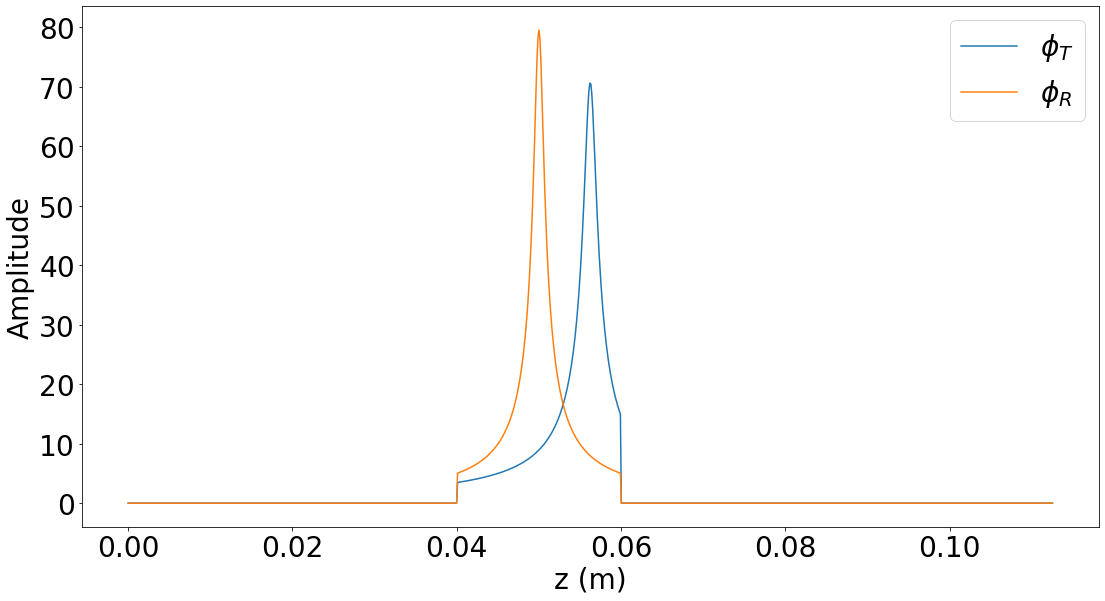

In [18]:
plt.plot(zF,p1*w(zF,0.04,0.06),label=r'$\phi_T$')
plt.plot(zF,p2*w(zF,0.04,0.06),label=r'$\phi_R$')
plt.legend()
plt.xlabel('z (m)')
plt.ylabel('Amplitude')
plt.tight_layout()
plt.savefig('fom_test')

In [19]:
p2[500]

7.879063310703427

In [20]:
prsq,prpt,ptsq=int_pairs(zF,0.04,0.06,p1,p2)

In [21]:
print(FOM(prsq,prpt,ptsq))

4.897448625304572


In [22]:
print(prpt)

4.468343558211096


In [23]:
print(prsq,prpt,ptsq)

11.460088458535274 4.468343558211096 11.990271182774777


In [24]:
prsq1,prpt1,ptsq1=int_pairs(zF,0.04,0.06,p1,p1)

In [25]:
print(prsq1,prpt1,ptsq1)

11.460088458535274 11.460088458535274 11.460088458535274


In [26]:
print(FOM(prsq1,prpt1,ptsq1))

0.0


In [27]:
i,f=retrieve_bounds(zF,0.05625-0.01,0.05625+0.01)
print(zF[i],zF[f])

0.04628378378378378 0.06632882882882883


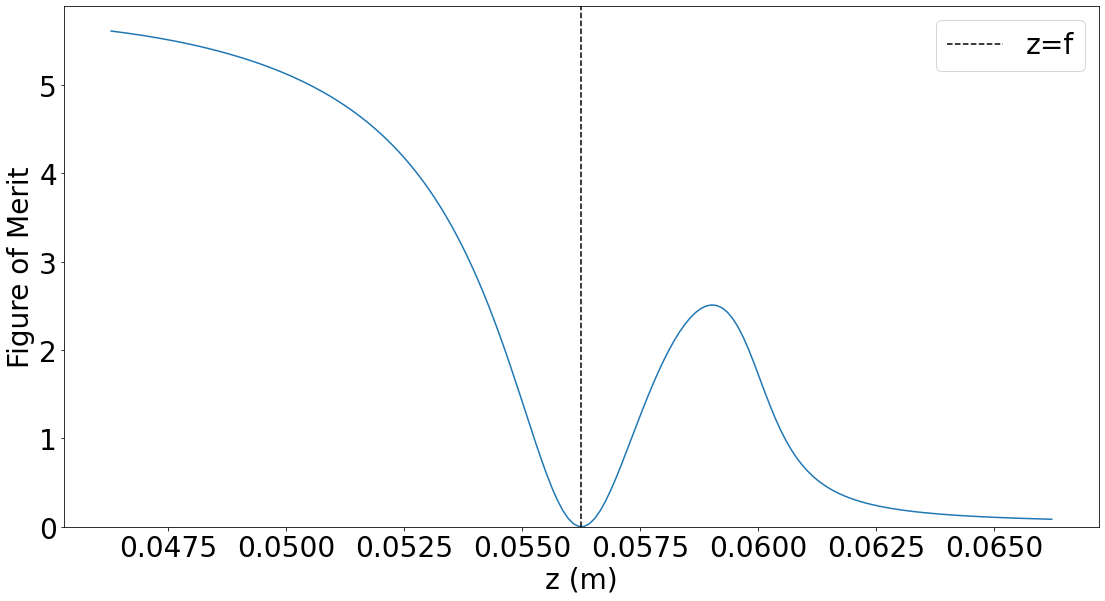

In [28]:
pt=amp(w0,wl,0.05625,zR,zF)
FOMs=[]
for j in range(i,f):
    pr=amp(w0,wl,zF[j],zR,zF)
    prsq,prpt,ptsq=int_pairs(zF,0.04,0.06,pr,pt)
    fom=FOM(prsq,prpt,ptsq)
    FOMs.append(fom)
    
plt.plot(zF[i:f],FOMs)
plt.axvline(0.05625,c='k',linestyle='--',label='z=f')
plt.xlabel('z (m)')
plt.ylabel('Figure of Merit')
plt.ylim(ymin=0)
plt.tight_layout()
plt.legend()
plt.savefig('fom')

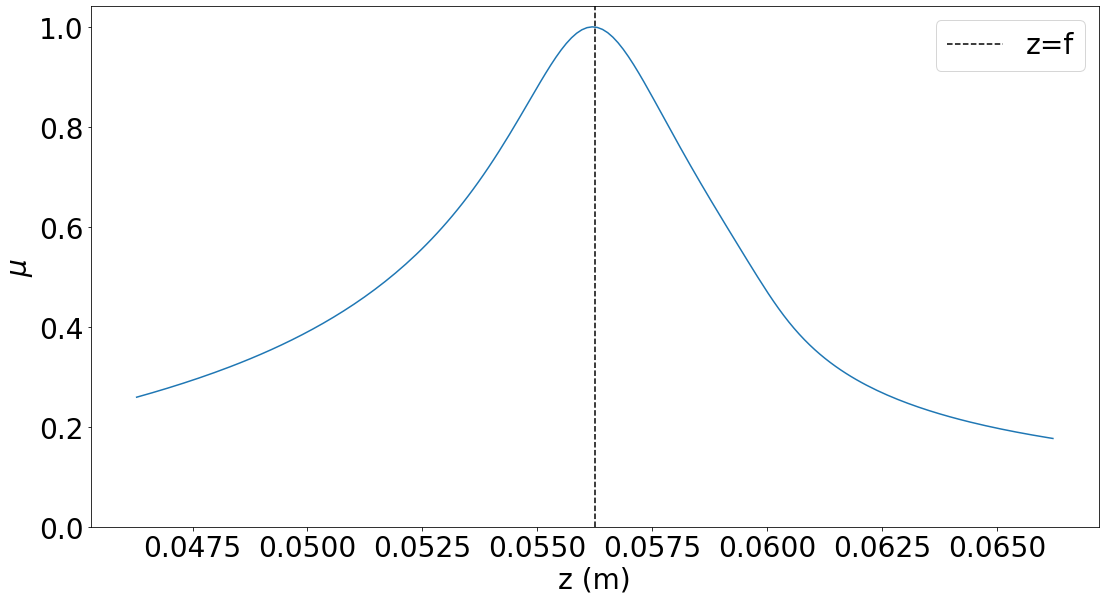

In [32]:
pt=amp(w0,wl,0.05625,zR,zF)
mus=[]
for j in range(i,f):
    pr=amp(w0,wl,zF[j],zR,zF)
    prsq,prpt,ptsq=int_pairs(zF,0.04,0.06,pr,pt)
    m=mu(prpt,ptsq)
    mus.append(m)
    
plt.plot(zF[i:f],mus)
plt.axvline(0.05625,c='k',linestyle='--',label='z=f')
plt.xlabel('z (m)')
plt.ylabel(r'$\mu$')
plt.ylim(ymin=0)
plt.tight_layout()
plt.legend()
plt.savefig('mu')